# Sistemas de Gerenciamento de Energia: estudo de caso

**Minicurso: Sistemas de Gerenciamento de Energia: Definições, Estratégias e Aplicação. Dia 2 (23/10)**

Ministrantes: José Vinícius Santos Freitas e Ruan Henrique Marques de Morais

O estudo de caso é um consumidor industrial do Grupo A (subgrupo A4), atendido pela Energisa Paraíba em João Pessoa. A pergunta que vamos responder:

> **Vale a pena instalar uma usina fotovoltaica (UFV), um sistema de armazenamento em baterias (BESS) ou os dois? Em qual modalidade tarifária?**

O notebook segue a ordem da ementa:

| Seção | Item da ementa |
|---|---|
| 1. Premissas | Estudo de caso |
| 2. Consumo | Definição de premissas de consumo |
| 3. Geração fotovoltaica | Prática de dimensionamento (recurso solar) |
| 4. Dimensionamento base | Prática de dimensionamento |
| 5. Cenários e balanço de energia | Definição dos cenários de análise |
| 6. Faturamento da rede | Faturamento da rede |
| 7. Estratégias de EMS | Aplicação de estratégias de EMS |
| 8. Análise do investimento | Custos evitados, comparação entre cenários, payback, fluxo de caixa, taxa de desconto e VPL |

Rode as células **em ordem**. Cada uma depende das anteriores.

In [1]:
try:
    import holidays
except ImportError:
    %pip install -q holidays
    import holidays

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paleta fixa: cada cenário/série mantém sempre a mesma cor em todos os gráficos
AZUL, LARANJA, VERDE_AGUA, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({
    'figure.figsize': (10, 4),
    'axes.prop_cycle': plt.cycler(color=[AZUL, LARANJA, VERDE_AGUA, AMARELO]),
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'lines.linewidth': 2,
})

## 1. Premissas

Todos os números do estudo ficam nesta célula. **Para os exercícios, mude só aqui e rode tudo de novo** (*Ambiente de execução → Executar tudo*).

Fontes:
- coordenadas e clima: NASA POWER;
- HSP de referência: CRESESB (SunData);
- módulo: datasheet Canadian Solar HiKu7 CS7N-650MS;
- custo do BESS: ABSAE (2025);
- tarifas: REH ANEEL nº 3.518/2025.

A lista completa está no fim do notebook.

In [2]:
# ---------- Local ----------
LATITUDE, LONGITUDE = -7.135, -34.842  # João Pessoa (PB)
ANO = 2025
HSP_CRESESB = 5.53                     # horas de sol pleno (kWh/m²/dia), CRESESB/SunData

# ---------- Consumo ----------
DEMANDA_BASE_KW = 140                  # kW que multiplica o perfil em p.u.
PERCENTUAL_RUIDO = 5                   # % das horas com um pico aleatório de carga

# ---------- Módulo fotovoltaico (datasheet CS7N-650MS) ----------
P_MODULO_KW = 0.650                    # potência nominal (kWp)
GAMA = -0.0034                         # coeficiente de temperatura da potência (1/°C)
NOCT = 41                              # temperatura nominal de operação da célula (°C)
PERDAS_UFV = 0.20                      # sujeira, cabos, inversor, mismatch...

# ---------- BESS ----------
SOC_MIN = 0.20                         # a bateria nunca desce de 20% (DoD = 80%)
CICLOS_VIDA = 6000                     # ciclos equivalentes até o fim de vida
SOH_FIM_VIDA = 0.80                    # fim de vida = 80% da capacidade original
LIMITE_PEAK_SHAVING_KW = 120           # acima disso, a estratégia de peak shaving descarrega

# ---------- Tarifação (REN 1.000/2021) ----------
HORARIO_PONTA = (18, 21)               # 18h às 21h, só em dias úteis
ICMS = 0.20                            # cobrado "por dentro"
CIP_MENSAL = 17.59                     # contribuição de iluminação pública (R$/mês)
TOLERANCIA_ULTRAPASSAGEM = 0.05        # medida até 5% acima da contratada não é multa
DEMANDA_MINIMA_KW = 30                 # menor demanda contratável no Grupo A

# ---------- Economia ----------
ANOS = 20
TAXA_DESCONTO = 0.05                   # taxa REAL: por isso não há reajuste tarifário
CAPEX_UFV = 2500                       # R$/kWp
CAPEX_BESS = 1362.54                   # R$/kWh (ABSAE, 2025)
OPEX_UFV = 0.002                       # fração do CAPEX por ano
OPEX_BESS = 0.0028
DEGRADACAO_UFV_ANO2 = 0.02             # datasheet: até 2% no 1º ano (aqui aplicado a partir do ano 2)...
DEGRADACAO_UFV_ANUAL = 0.0055          # ...e até 0,55% ao ano depois

## 2. Consumo

Não temos a curva de carga medida do cliente, então vamos montar uma curva sintética com quatro ingredientes:

1. **Perfil diário em p.u.**, um para cada tipo de dia: dia útil, fim de semana e feriado.
2. **Calendário**: feriados nacionais e estaduais (PB), mais Carnaval e Corpus Christi, via biblioteca `holidays`. O feriado também pode mudar o **posto tarifário**: pela REN 1.000/2021, não há ponta nos feriados nacionais, na terça de Carnaval e em Corpus Christi. O feriado estadual (05/08) e a segunda de Carnaval mudam só a carga.
3. **Sazonalidade**: um fator por mês (a indústria consome menos no meio do ano).
4. **Ruído**: em 5% das horas a carga dá um pico entre 100% e 125% da demanda base. É ele que define os **picos de demanda** e, com isso, a demanda contratada. No ano 1 não há ultrapassagem, porque contratamos o maior pico medido; ela aparece nos anos seguintes, quando a bateria envelhece.

$$\text{Consumo}(h) = D_{base} \cdot \text{p.u.}_{\text{tipo de dia}}(\text{hora}) \cdot f_{\text{mês}}$$

Como o passo é de 1 hora, a energia da hora (kWh) e a potência média da hora (kW) têm o mesmo número.

In [3]:
horas = pd.date_range(f'{ANO}-01-01', periods=8760, freq='h')

# Curva de carga: feriados nacionais + estaduais da Paraíba, mais Carnaval e Corpus Christi
# (pontos facultativos). Feriados municipais ficam de fora.
feriados = holidays.Brazil(years=ANO, subdiv='PB')
for data, nome in holidays.Brazil(years=ANO, subdiv='PB', categories=('optional',)).items():
    if 'arnaval' in nome or 'Corpus' in nome:
        feriados[data] = nome

eh_feriado = horas.normalize().isin(pd.to_datetime(list(feriados)))

# Posto tarifário (REN 1.000/2021, art. 2º): sem ponta só nos feriados nacionais, na terça de Carnaval
# e em Corpus Christi. Feriado estadual e segunda de Carnaval mudam a carga, mas não o posto.
nacionais = holidays.Brazil(years=ANO)
sem_ponta = [d for d, nome in feriados.items()
             if d in nacionais or nome == 'Corpus Christi' or (nome == 'Carnaval' and d.weekday() == 1)]
dia_util = (horas.dayofweek < 5) & ~horas.normalize().isin(pd.to_datetime(sem_ponta))
ponta = dia_util & (horas.hour >= HORARIO_PONTA[0]) & (horas.hour < HORARIO_PONTA[1])

print(f'{len(feriados)} feriados em {ANO}:')
for data, nome in sorted(feriados.items()):
    print(f'  {data:%d/%m}  {nome}' + ('  (sem ponta)' if data in sem_ponta else ''))

14 feriados em 2025:
  01/01  Confraternização Universal  (sem ponta)
  03/03  Carnaval
  04/03  Carnaval  (sem ponta)
  18/04  Sexta-feira Santa  (sem ponta)
  21/04  Tiradentes  (sem ponta)
  01/05  Dia do Trabalhador  (sem ponta)
  19/06  Corpus Christi  (sem ponta)
  05/08  Fundação do Estado
  07/09  Independência do Brasil  (sem ponta)
  12/10  Nossa Senhora Aparecida  (sem ponta)
  02/11  Finados  (sem ponta)
  15/11  Proclamação da República  (sem ponta)
  20/11  Dia Nacional de Zumbi e da Consciência Negra  (sem ponta)
  25/12  Natal  (sem ponta)


In [4]:
# Perfil diário em p.u. (hora 0 a 23)
perfil = pd.DataFrame({
    'Dia útil':      [0.2,0.2,0.2,0.2,0.3,0.3,0.4,0.7,0.8,0.8,0.8,0.8,0.9,0.9,0.9,0.8,0.8,0.8,0.7,0.7,0.7,0.4,0.3,0.2],
    'Fim de semana': [0.1,0.1,0.1,0.1,0.2,0.2,0.4,0.6,0.8,0.9,0.9,1.0,1.0,1.0,1.0,1.0,0.9,0.9,0.9,0.9,0.9,0.7,0.4,0.2],
    'Feriado':       [0.0,0.1,0.1,0.1,0.1,0.1,0.3,0.5,0.6,0.9,0.9,1.0,1.0,1.0,1.0,1.0,0.9,0.9,0.8,0.8,0.5,0.1,0.1,0.0],
})
sazonalidade = np.array([1.0, 1.0, 0.9, 0.9, 0.8, 0.75, 0.75, 0.8, 0.9, 0.9, 1.0, 1.0])  # jan..dez

tipo_dia = np.where(eh_feriado, 'Feriado', np.where(horas.dayofweek >= 5, 'Fim de semana', 'Dia útil'))
pu = perfil.to_numpy()[horas.hour, perfil.columns.get_indexer(tipo_dia)]
consumo = DEMANDA_BASE_KW * pu * sazonalidade[horas.month - 1]

# Ruído: semente fixa para todos na sala obterem os mesmos números
rng = np.random.default_rng(2)
sorteadas = rng.random(len(horas)) < PERCENTUAL_RUIDO / 100
consumo[sorteadas] = DEMANDA_BASE_KW * (1 + 0.25 * rng.random(sorteadas.sum()))

consumo = pd.Series(consumo, index=horas, name='Consumo (kWh)')
print(f'Consumo anual: {consumo.sum():,.0f} kWh  |  médio diário: {consumo.sum() / 365:,.0f} kWh')
print(f'Pico: {consumo.max():.0f} kW  |  horas acima de {DEMANDA_BASE_KW} kW: {(consumo > DEMANDA_BASE_KW).sum()}')

Consumo anual: 677,473 kWh  |  médio diário: 1,856 kWh
Pico: 175 kW  |  horas acima de 140 kW: 408


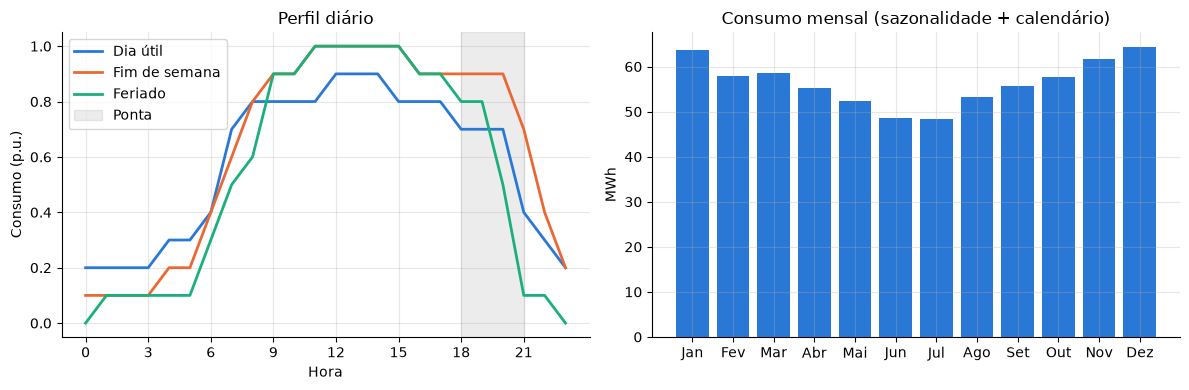

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for coluna in perfil:
    ax1.plot(perfil.index, perfil[coluna], label=coluna)
ax1.axvspan(*HORARIO_PONTA, color='gray', alpha=0.15, label='Ponta')
ax1.set(title='Perfil diário', xlabel='Hora', ylabel='Consumo (p.u.)', xticks=range(0, 24, 3))
ax1.legend()

consumo_mensal = consumo.resample('ME').sum() / 1000
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
ax2.bar(MESES, consumo_mensal, color=AZUL)
ax2.set(title='Consumo mensal (sazonalidade + calendário)', ylabel='MWh')
plt.tight_layout()

## 3. Geração fotovoltaica

### 3.1 Recurso solar

Os dados horários de irradiância (`ALLSKY_SFC_SW_DWN`) e temperatura do ar a 2 m (`T2M`) vêm da **NASA POWER**. A célula abaixo mostra como baixá-los. Ela fica comentada para a aula não depender da internet: o arquivo já está no repositório.

In [6]:
# import requests
# resposta = requests.get('https://power.larc.nasa.gov/api/temporal/hourly/point', params={
#     'parameters': 'ALLSKY_SFC_SW_DWN,T2M', 'community': 'AG',
#     'latitude': LATITUDE, 'longitude': LONGITUDE,
#     'start': f'{ANO}0101', 'end': f'{ANO}1231', 'format': 'CSV', 'time-standard': 'UTC',
# }, timeout=60)
# Path('dados_nasa_power.csv').write_bytes(resposta.content)

Três tratamentos antes de usar o dado:
- **Fuso**: a NASA entrega em UTC e João Pessoa está em UTC−3.
- **Unidade**: a irradiação vem em MJ/m² por hora. Dividindo por 3,6 temos kWh/m² na hora, que é numericamente a irradiância média em kW/m².
- **Calibração**: o dado de satélite é grosseiro (pixel de ~50 km). Escalamos a série para que a média diária bata com o HSP medido do **CRESESB** (5,53 h). A forma horária vem da NASA; o total anual, do CRESESB.

In [7]:
ARQUIVO = 'dados_nasa_power.csv'
URL = 'https://raw.githubusercontent.com/jviniciiuss/minicurso-ems/main/dados_nasa_power.csv'
clima = pd.read_csv(ARQUIVO if Path(ARQUIVO).exists() else URL, header=10)  # 10 linhas de cabeçalho da NASA

instante_utc = pd.to_datetime(clima[['YEAR', 'MO', 'DY', 'HR']].set_axis(['year', 'month', 'day', 'hour'], axis=1))
clima.index = pd.DatetimeIndex(instante_utc.dt.tz_localize('UTC').dt.tz_convert('America/Recife').dt.tz_localize(None))
clima = clima.reindex(horas)  # as 3 últimas horas de 31/12 (local) caem em 2026 UTC: viram NaN (é noite)

irradiancia = (clima['ALLSKY_SFC_SW_DWN'].clip(lower=0) / 3.6).fillna(0)        # kW/m² (média da hora)
temperatura_ar = clima['T2M'].where(clima['T2M'] > -50).interpolate().bfill()  # -999 = dado ausente

hsp_nasa = irradiancia.sum() / 365
irradiancia *= HSP_CRESESB / hsp_nasa
print(f'HSP NASA: {hsp_nasa:.2f} h  ->  calibrado para o CRESESB: {irradiancia.sum() / 365:.2f} h')

HSP NASA: 5.90 h  ->  calibrado para o CRESESB: 5.53 h


### 3.2 Temperatura da célula e potência

Quanto mais quente o módulo, menos ele gera. A temperatura da célula sobe com a irradiância, e o **NOCT** (do datasheet) diz quanto:

$$T_{cel} = T_{amb} + \frac{NOCT - 20}{800} \cdot G \quad (G \text{ em W/m}^2)$$

Com ela, a potência por kWp instalado é:

$$P = P_{nom} \cdot \frac{G}{1000} \cdot \left[1 + \gamma\,(T_{cel} - 25)\right] \cdot (1 - \text{perdas})$$

In [8]:
temperatura_celula = temperatura_ar + (NOCT - 20) / 800 * irradiancia * 1000
geracao_por_kwp = irradiancia * (1 + GAMA * (temperatura_celula - 25)) * (1 - PERDAS_UFV)  # kWh/kWp na hora

perda_termica = 1 - geracao_por_kwp.sum() / (irradiancia.sum() * (1 - PERDAS_UFV))
print(f'Perda por temperatura no ano: {perda_termica:.1%}')

Perda por temperatura no ano: 7.2%


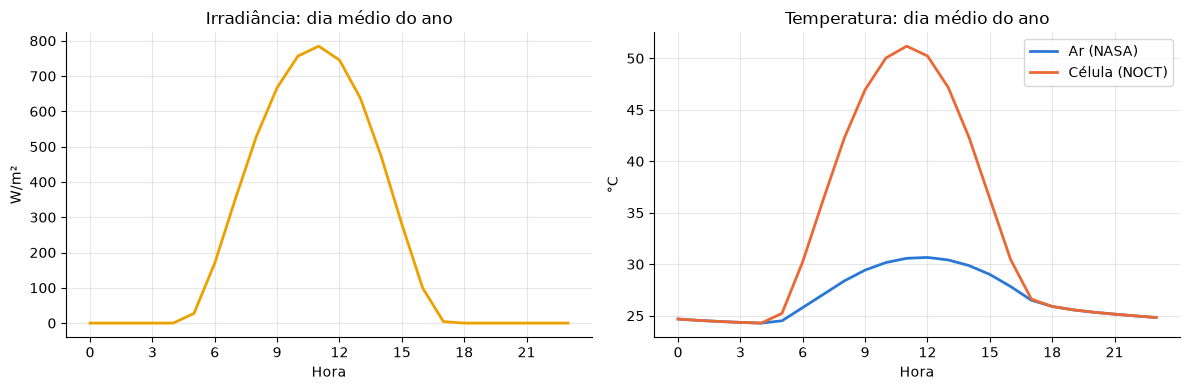

In [9]:
dia_medio = lambda serie: serie.groupby(serie.index.hour).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(dia_medio(irradiancia * 1000), color=AMARELO)
ax1.set(title='Irradiância: dia médio do ano', xlabel='Hora', ylabel='W/m²', xticks=range(0, 24, 3))

ax2.plot(dia_medio(temperatura_ar), label='Ar (NASA)')
ax2.plot(dia_medio(temperatura_celula), label='Célula (NOCT)')
ax2.set(title='Temperatura: dia médio do ano', xlabel='Hora', ylabel='°C', xticks=range(0, 24, 3))
ax2.legend()
plt.tight_layout()

## 4. Dimensionamento base

### UFV
Dimensionamos a usina para gerar, no ano, a energia que o cliente consome. Para isso, dividimos o consumo anual pela **produtividade** do local, que é quanto cada kWp gera em um ano, já com temperatura e perdas:

$$P_{UFV} = \frac{\text{Consumo anual}}{\text{Produtividade}} \qquad \text{Produtividade} = HSP \cdot 365 \cdot PR$$

### BESS
A bateria precisa atravessar a ponta inteira sem comprar da rede:
- **Energia**: a maior energia consumida na ponta em um dia, dividida pelo DoD (a fração que usamos sem descer do SoC mínimo). Usamos o *pior* dia, porque um único dia descoberto já registra demanda na ponta naquele mês.
- **Potência**: o maior pico de carga na ponta.

In [10]:
consumo_anual = consumo.sum()
produtividade = geracao_por_kwp.sum()                 # kWh/kWp/ano
PR = produtividade / (HSP_CRESESB * 365)

n_modulos = int(np.ceil(consumo_anual / produtividade / P_MODULO_KW))
P_UFV = n_modulos * P_MODULO_KW

energia_ponta_diaria = consumo[ponta].groupby(consumo[ponta].index.date).sum()
E_BESS = 5 * np.ceil(energia_ponta_diaria.max() / (1 - SOC_MIN) / 5)   # kWh, múltiplo de 5
P_BESS = 5 * np.ceil(consumo[ponta].max() / 5)                          # kW, múltiplo de 5

print(f'Produtividade: {produtividade:,.0f} kWh/kWp/ano  (PR = {PR:.1%})')
print(f'UFV:  {n_modulos} módulos x {P_MODULO_KW * 1000:.0f} W = {P_UFV:.1f} kWp')
print(f'BESS: {E_BESS:.0f} kWh / {P_BESS:.0f} kW  (C-rate = {P_BESS / E_BESS:.2f}C, DoD = {1 - SOC_MIN:.0%})')

Produtividade: 1,499 kWh/kWp/ano  (PR = 74.3%)
UFV:  696 módulos x 650 W = 452.4 kWp
BESS: 460 kWh / 175 kW  (C-rate = 0.38C, DoD = 80%)


## 5. Cenários e balanço de energia

| Cenário | UFV | BESS | Como a bateria carrega |
|---|---|---|---|
| **C1** Só rede | – | – | – |
| **C2** Rede + UFV | ✔ | – | – |
| **C3** Rede + BESS | – | ✔ | Da rede, fora da ponta |
| **C4** Rede + UFV + BESS | ✔ | ✔ | Só com o excedente solar |

O balanço de energia em cada hora é:

$$\text{Rede} = \text{Consumo} - \text{Geração} + \text{Bateria}$$

Convenção de sinais: **Rede > 0 é importação** (compra) e **Rede < 0 é injeção**. **Bateria > 0 é carga**, Bateria < 0 é descarga.

Antes de entrar a bateria (seção 7), vejamos C1 e C2.

Geração: 678,040 kWh  |  injetado na rede: 296,001 kWh (44%)


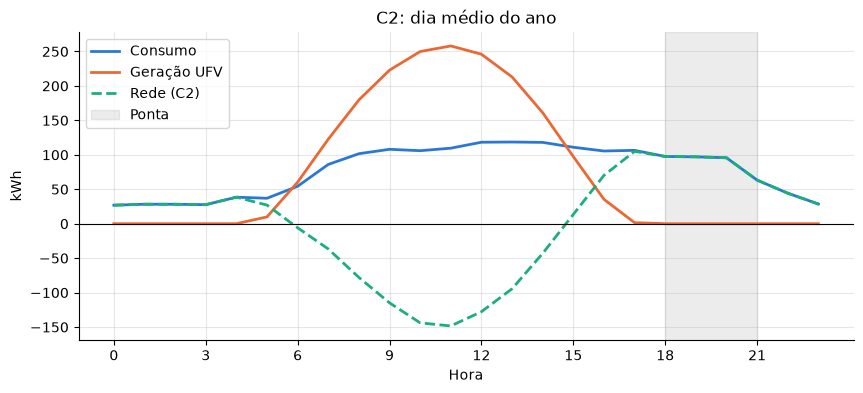

In [11]:
geracao_ufv = P_UFV * geracao_por_kwp

fig, ax = plt.subplots()
ax.plot(dia_medio(consumo), label='Consumo')
ax.plot(dia_medio(geracao_ufv), label='Geração UFV')
ax.plot(dia_medio(consumo - geracao_ufv), label='Rede (C2)', linestyle='--')
ax.axhline(0, color='black', linewidth=0.8)
ax.axvspan(*HORARIO_PONTA, color='gray', alpha=0.15, label='Ponta')
ax.set(title='C2: dia médio do ano', xlabel='Hora', ylabel='kWh', xticks=range(0, 24, 3))
ax.legend()

injetado = (geracao_ufv - consumo).clip(lower=0).sum()
print(f'Geração: {geracao_ufv.sum():,.0f} kWh  |  injetado na rede: {injetado:,.0f} kWh ({injetado / geracao_ufv.sum():.0%})')

## 6. Faturamento da rede

Consumidor A4 horossazonal: a conta tem **energia** (R$/kWh, por posto) e **demanda** (R$/kW, sobre o valor contratado). Comparamos as duas modalidades:

| | Energia | Demanda |
|---|---|---|
| **Azul** | Tarifa de ponta ≈ 1,4× a fora de ponta | **Dupla**: ponta (cara) e fora de ponta |
| **Verde** | Tarifa de ponta ≈ 4× a fora de ponta | **Única** |

Tarifas da Energisa Paraíba, **REH ANEEL nº 3.518/2025** (vigência 2026.2), sem tributos.

In [12]:
TE = {'p': 0.42819, 'fp': 0.24537}                       # R$/kWh, igual nas duas modalidades
TUSD_ENERGIA = {'azul':  {'p': 0.12652, 'fp': 0.16252},  # R$/kWh
                'verde': {'p': 1.28990, 'fp': 0.16252}}
TUSD_DEMANDA = {'azul':  {'p': 47.91, 'fp': 24.21},      # R$/kW
                'verde': {'unica': 24.21}}

# Tabela 4 da REH: desconto sobre a TE e a TUSD da energia COMPENSADA (1 = desconto integral)
DESCONTO_SCEE = {'azul':  {'tusd_p': 1.0, 'tusd_fp': 1.0, 'te_p': 1.0,    'te_fp': 1.0},
                 'verde': {'tusd_p': 1.0, 'tusd_fp': 1.0, 'te_p': 0.5040, 'te_fp': 1.0}}

for modalidade in ('azul', 'verde'):
    tusd = TUSD_ENERGIA[modalidade]
    print(f"{modalidade:>5}: consumo ponta R$ {TE['p'] + tusd['p']:.4f}/kWh | fora ponta R$ {TE['fp'] + tusd['fp']:.4f}/kWh")

 azul: consumo ponta R$ 0.5547/kWh | fora ponta R$ 0.4079/kWh
verde: consumo ponta R$ 1.7181/kWh | fora ponta R$ 0.4079/kWh


### 6.1 Do horário para o mensal

A fatura é mensal. De cada mês, por posto (ponta = `p`, fora de ponta = `fp`), tiramos:
- **energia importada** e **energia injetada** (kWh);
- **demanda medida** (kW): a maior importação horária. Na azul ela é medida por posto; na verde, uma só.

In [13]:
def resumo_mensal(rede):
    """Agrega a série horária da rede (> 0 importa, < 0 injeta) em mês x posto."""
    importa, injeta = rede.clip(lower=0), (-rede).clip(lower=0)
    tabela = pd.DataFrame({
        'imp_p': importa.where(ponta, 0), 'imp_fp': importa.where(~ponta, 0),
        'inj_p': injeta.where(ponta, 0),  'inj_fp': injeta.where(~ponta, 0),
        'dem_p': importa.where(ponta, 0), 'dem_fp': importa.where(~ponta, 0), 'dem': importa,
    })
    return tabela.resample('ME').agg({'imp_p': 'sum', 'imp_fp': 'sum', 'inj_p': 'sum', 'inj_fp': 'sum',
                                      'dem_p': 'max', 'dem_fp': 'max', 'dem': 'max'})

resumo_mensal(consumo - geracao_ufv).round(0)

,imp_p,imp_fp,inj_p,inj_fp,dem_p,dem_fp,dem
2025-01-31,6640.0,20302.0,0.0,24322.0,162.0,174.0,174.0
2025-02-28,6001.0,19490.0,0.0,21582.0,162.0,169.0,169.0
2025-03-31,5473.0,19560.0,0.0,27154.0,159.0,173.0,173.0
2025-04-30,5363.0,18182.0,0.0,24453.0,159.0,171.0,171.0
2025-05-31,5289.0,18774.0,0.0,21737.0,174.0,173.0,174.0
2025-06-30,4744.0,17465.0,0.0,20751.0,169.0,174.0,174.0
2025-07-31,5156.0,16151.0,0.0,19226.0,158.0,175.0,175.0
2025-08-31,5184.0,18348.0,0.0,24519.0,169.0,174.0,174.0
2025-09-30,5901.0,18666.0,0.0,24974.0,168.0,174.0,174.0
2025-10-31,6336.0,18627.0,0.0,30705.0,171.0,175.0,175.0


### 6.2 Demanda contratada e ultrapassagem

**Regra simples do minicurso:** contratar o maior pico medido no ano, arredondado para cima em múltiplos de 5 kW e respeitando o mínimo de 30 kW (na azul, basta que um dos postos chegue a 30 kW; REN 1.000/2021, art. 148). Em cada mês, paga-se o **maior** valor entre contratada e medida. Se a medida passar a contratada em mais de 5% (tolerância), o excedente paga **2×** a tarifa **além** do faturamento normal, ou seja, 3× no total (REN 1.000/2021, art. 301).

*Simplificação: o ICMS incide sobre toda a demanda faturada, inclusive a parte contratada e não usada. Pela Súmula 391 do STJ, ele só incide sobre a demanda efetivamente utilizada. Isso encarece as contas com demanda ociosa (sobretudo na azul) e subestima o custo evitado.*

In [14]:
def demanda_contratada(mensal, modalidade):
    arredonda = lambda kw: 5 * np.ceil(kw / 5)
    if modalidade == 'azul':                           # mínimo de 30 kW em pelo menos um dos postos
        p, fp = arredonda(mensal['dem_p'].max()), arredonda(mensal['dem_fp'].max())
        return {'p': p, 'fp': max(fp, DEMANDA_MINIMA_KW) if p < DEMANDA_MINIMA_KW else fp}
    return {'unica': max(DEMANDA_MINIMA_KW, arredonda(mensal['dem'].max()))}


def custo_demanda(medida, contratada, tarifa):
    custo = max(contratada, medida) * tarifa
    if medida > (1 + TOLERANCIA_ULTRAPASSAGEM) * contratada:
        custo += 2 * tarifa * (medida - contratada)   # ultrapassagem: soma-se ao faturamento normal
    return custo

### 6.3 Compensação de energia (SCEE)

A energia injetada vira **crédito** (Lei 14.300/2022; REN 1.000/2021, art. 655-G):
1. Primeiro abate o consumo do **mesmo posto**, 1 kWh por 1 kWh.
2. A sobra abate o **outro posto**, convertida pela razão entre as TE dos postos (fator de ajuste).
3. O que restar fica guardado para os meses seguintes.

A energia compensada não sai de graça: sobre ela incide a **tarifa de aplicação** da Tabela 4 da REH, a parcela que o desconto não cobre:

$$\text{Tarifa de aplicação} = (1 - d_{TUSD}) \cdot TUSD + (1 - d_{TE}) \cdot TE$$

É por aqui que a transição da Lei 14.300 chega à conta.

*Simplificação: no mundo real o crédito expira em 60 meses e é consumido do mais antigo para o mais novo (FIFO). Aqui o saldo só se acumula.*

In [15]:
def faturar(mensal, modalidade, contratada, credito_p=0.0, credito_fp=0.0):
    """Fatura mês a mês. Retorna a fatura (R$) e o saldo de créditos (kWh) no fim."""
    tusd, desconto = TUSD_ENERGIA[modalidade], DESCONTO_SCEE[modalidade]
    tarifa = {posto: TE[posto] + tusd[posto] for posto in ('p', 'fp')}
    aplicacao = {posto: (1 - desconto[f'tusd_{posto}']) * tusd[posto] + (1 - desconto[f'te_{posto}']) * TE[posto]
                 for posto in ('p', 'fp')}
    fator = TE['fp'] / TE['p']   # 1 kWh de crédito fora de ponta abate `fator` kWh na ponta

    linhas = []
    for mes, m in mensal.iterrows():
        falta_p, falta_fp = m['imp_p'], m['imp_fp']
        credito_p += m['inj_p']
        credito_fp += m['inj_fp']
        # 1) mesmo posto, 1:1
        usa = min(falta_p, credito_p);  falta_p -= usa;  credito_p -= usa
        usa = min(falta_fp, credito_fp); falta_fp -= usa; credito_fp -= usa
        # 2) posto cruzado, com o fator de ajuste
        usa = min(falta_p, credito_fp * fator);  falta_p -= usa;  credito_fp -= usa / fator
        usa = min(falta_fp, credito_p / fator);  falta_fp -= usa; credito_p -= usa * fator

        energia = falta_p * tarifa['p'] + falta_fp * tarifa['fp']
        compensada = (m['imp_p'] - falta_p) * aplicacao['p'] + (m['imp_fp'] - falta_fp) * aplicacao['fp']
        if modalidade == 'azul':
            demanda = (custo_demanda(m['dem_p'], contratada['p'], TUSD_DEMANDA['azul']['p'])
                       + custo_demanda(m['dem_fp'], contratada['fp'], TUSD_DEMANDA['azul']['fp']))
        else:
            demanda = custo_demanda(m['dem'], contratada['unica'], TUSD_DEMANDA['verde']['unica'])
        sem_imposto = energia + compensada + demanda
        linhas.append({'Energia': energia, 'Compensada': compensada, 'Demanda': demanda,
                       'ICMS': sem_imposto * ICMS / (1 - ICMS), 'CIP': CIP_MENSAL})

    fatura = pd.DataFrame(linhas, index=mensal.index)
    fatura['Total'] = fatura.sum(axis=1)
    return fatura, (credito_p, credito_fp)

In [16]:
def conta_anual(rede, modalidade):
    mensal = resumo_mensal(rede)
    contratada = demanda_contratada(mensal, modalidade)
    fatura, _ = faturar(mensal, modalidade, contratada)
    return fatura.sum().rename(f'{modalidade}'), contratada

for nome, rede in {'C1': consumo, 'C2': consumo - geracao_ufv}.items():
    tabela = pd.DataFrame([conta_anual(rede, m)[0] for m in ('azul', 'verde')])
    print(f'\n{nome}: conta anual (R$)')
    print(tabela.round(0).to_string())


C1: conta anual (R$)
        Energia  Compensada   Demanda      ICMS    CIP     Total
azul   286392.0         0.0  151452.0  109461.0  211.0  547516.0
verde  366083.0         0.0   50841.0  104231.0  211.0  521367.0



C2: conta anual (R$)
       Energia  Compensada   Demanda     ICMS    CIP     Total
azul   16043.0         0.0  151452.0  41874.0  211.0  209580.0
verde  49691.0      8406.0   50841.0  27234.0  211.0  136383.0


**Para discutir:** em C1 a azul ou a verde é mais barata? Por quê? E em C2, de onde vem o que sobra na conta, se a UFV gera 100% do consumo anual?

## 7. Estratégias de EMS

O EMS decide, **hora a hora**, o que a bateria faz. Usamos regras explícitas (*rule-based*), sem otimização:

| Estratégia | Descarrega quando… | Carrega quando… |
|---|---|---|
| **Time shifting** | é horário de ponta | há sobra solar, ou fora da ponta pela rede (C3), sem passar do pico fora de ponta |
| **Peak shaving** | a carga líquida passa do limite (kW) | há sobra solar, ou pela rede (C3), sem passar do limite |

Sempre respeitando: **SoC mínimo** (DoD), **SoC máximo** (capacidade × SoH) e **potência** do inversor (C-rate).

*Simplificação: a bateria não tem perdas: cada kWh carregado volta inteiro na descarga (eficiência de ida e volta de 100%). Uma bateria LFP real fica perto de 90%; com isso, o VPL do C3 cairia cerca de R$ 50 a 60 mil.*

In [17]:
def despachar(consumo, geracao, E, P, estrategia, carrega_da_rede):
    """Despacho por regras, hora a hora. Retorna a bateria (kWh na hora: + carga, - descarga) e o SoC."""
    liquido = (consumo - geracao).to_numpy()           # > 0 falta energia; < 0 sobra solar
    if estrategia == 'peak_shaving':
        limite = LIMITE_PEAK_SHAVING_KW
    else:
        limite = consumo[~ponta].max()                 # carregar sem criar pico novo fora da ponta
    soc_min, soc_max = SOC_MIN * E, E

    bateria, soc_hora = np.zeros(len(liquido)), np.zeros(len(liquido))
    soc = soc_min
    for i, liq in enumerate(liquido):
        if estrategia == 'time_shifting':
            descarrega, alvo = ponta[i], liq             # na ponta, cobre a carga inteira
        else:
            descarrega, alvo = liq > limite, liq - limite  # só corta o que passa do limite

        if descarrega:
            fluxo = -min(max(alvo, 0), P, soc - soc_min)
        elif liq < 0:                                  # sobra solar
            fluxo = min(-liq, P, soc_max - soc)
        elif carrega_da_rede and not ponta[i]:
            fluxo = min(max(limite - liq, 0), P, soc_max - soc)
        else:
            fluxo = 0.0
        soc += fluxo
        bateria[i], soc_hora[i] = fluxo, soc
    return pd.Series(bateria, index=consumo.index), pd.Series(soc_hora, index=consumo.index)


CENARIOS = {'C1': dict(ufv=False, bess=False), 'C2': dict(ufv=True, bess=False),
            'C3': dict(ufv=False, bess=True),  'C4': dict(ufv=True, bess=True)}

def simular(ufv, bess, estrategia='time_shifting', soh_ufv=1.0, soh_bess=1.0):
    geracao = geracao_ufv * soh_ufv if ufv else consumo * 0
    if bess:
        bateria, soc = despachar(consumo, geracao, E_BESS * soh_bess, P_BESS, estrategia, carrega_da_rede=not ufv)
    else:
        bateria = soc = consumo * 0
    return pd.DataFrame({'Consumo': consumo, 'Geração': geracao, 'Bateria': bateria, 'SoC': soc,
                         'Rede': consumo - geracao + bateria})

simulacoes = {nome: simular(**c) for nome, c in CENARIOS.items()}

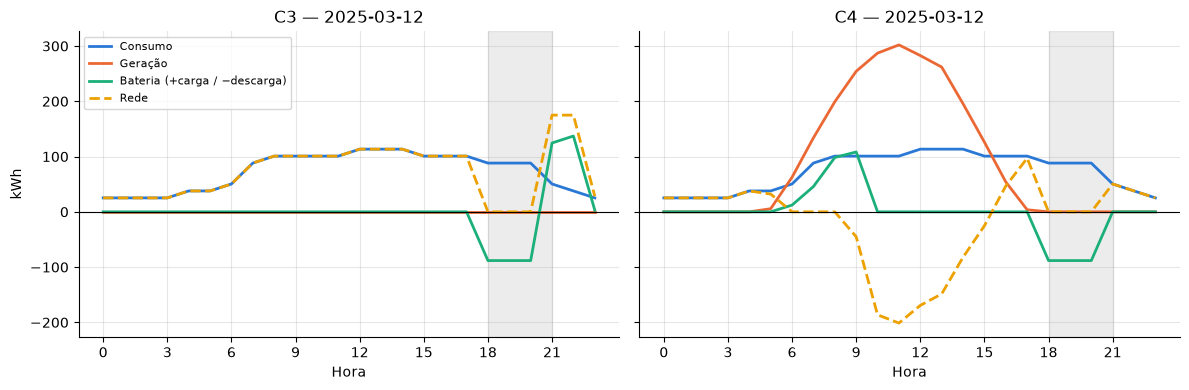

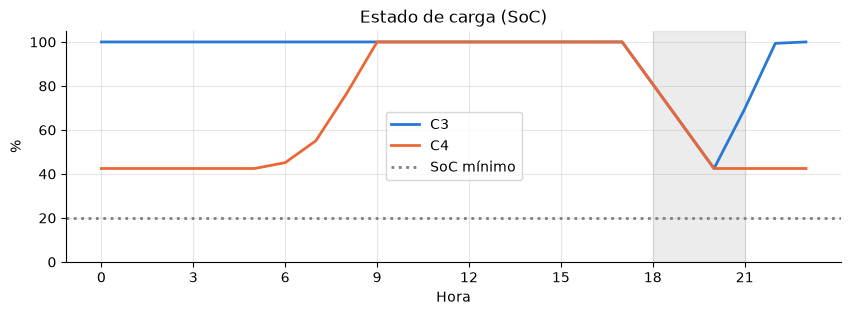

In [18]:
# Um dia útil para ver a bateria trabalhando
DIA = '2025-03-12'
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nome in zip(eixos, ('C3', 'C4')):
    d = simulacoes[nome].loc[DIA]
    ax.plot(d.index.hour, d['Consumo'], label='Consumo')
    ax.plot(d.index.hour, d['Geração'], label='Geração')
    ax.plot(d.index.hour, d['Bateria'], label='Bateria (+carga / −descarga)')
    ax.plot(d.index.hour, d['Rede'], label='Rede', linestyle='--')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvspan(*HORARIO_PONTA, color='gray', alpha=0.15)
    ax.set(title=f'{nome} — {DIA}', xlabel='Hora', xticks=range(0, 24, 3))
eixos[0].set_ylabel('kWh')
eixos[0].legend(fontsize=8)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(10, 3))
for nome in ('C3', 'C4'):
    ax.plot(simulacoes[nome].loc[DIA, 'SoC'].to_numpy() / E_BESS * 100, label=nome)
ax.axhline(SOC_MIN * 100, color='gray', linestyle=':', label='SoC mínimo')
ax.axvspan(*HORARIO_PONTA, color='gray', alpha=0.15)
ax.set(title='Estado de carga (SoC)', xlabel='Hora', ylabel='%', xticks=range(0, 24, 3), ylim=(0, 105))
ax.legend()

In [19]:
contas = {}
for nome, sim in simulacoes.items():
    for modalidade in ('azul', 'verde'):
        contas[(nome, modalidade)], _ = conta_anual(sim['Rede'], modalidade)
contas = pd.DataFrame(contas).T
contas.index.names = ['Cenário', 'Modalidade']
contas.round(0)

Energia  Compensada   Demanda      ICMS    CIP     Total
Cenário Modalidade                                                           
C1      azul        286392.0         0.0  151452.0  109461.0  211.0  547516.0
        verde       366083.0         0.0   50841.0  104231.0  211.0  521367.0
C2      azul         16043.0         0.0  151452.0   41874.0  211.0  209580.0
        verde        49691.0      8406.0   50841.0   27234.0  211.0  136383.0
C3      azul        276485.0         0.0   50841.0   81831.0  211.0  409368.0
        verde       276485.0         0.0   50841.0   81831.0  211.0  409368.0
C4      azul          4015.0         0.0  108333.0   28087.0  211.0  140646.0
        verde         4532.0        69.0   50841.0   13860.0  211.0   69514.0

### 7.1 Time shifting × peak shaving

A mesma bateria (C3), com outra regra. Observe **qual componente da conta** cada estratégia ataca, e em qual modalidade isso vale mais.

In [20]:
comparacao = {}
for estrategia in ('time_shifting', 'peak_shaving'):
    rede = simular(ufv=False, bess=True, estrategia=estrategia)['Rede']
    for modalidade in ('azul', 'verde'):
        comparacao[(estrategia, modalidade)], _ = conta_anual(rede, modalidade)
comparacao = pd.DataFrame(comparacao).T
comparacao.index.names = ['Estratégia (C3)', 'Modalidade']
comparacao.round(0)

Energia  Compensada   Demanda     ICMS    CIP  \
Estratégia (C3) Modalidade                                                   
time_shifting   azul        276485.0         0.0   50841.0  81831.0  211.0   
                verde       276485.0         0.0   50841.0  81831.0  211.0   
peak_shaving    azul        286366.0         0.0  103853.0  97555.0  211.0   
                verde       364667.0         0.0   34862.0  99882.0  211.0   

                               Total  
Estratégia (C3) Modalidade            
time_shifting   azul        409368.0  
                verde       409368.0  
peak_shaving    azul        487985.0  
                verde       499623.0

## 8. Análise do investimento

### 8.1 Custos evitados (ano 1)

A "receita" de UFV e BESS é a **conta que deixa de ser paga**: custo evitado = conta de C1 − conta do cenário, componente por componente.

In [21]:
evitado = {}
for (nome, modalidade), linha in contas.iterrows():
    if nome != 'C1':
        evitado[(nome, modalidade)] = contas.loc[('C1', modalidade)] - linha
evitado = pd.DataFrame(evitado).T
evitado.index.names = ['Cenário', 'Modalidade']
evitado.round(0)

Energia  Compensada   Demanda     ICMS  CIP     Total
Cenário Modalidade                                                        
C2      azul        270348.0         0.0       0.0  67587.0  0.0  337936.0
        verde       316393.0     -8406.0       0.0  76997.0  0.0  384984.0
C3      azul          9907.0         0.0  100611.0  27630.0  0.0  138148.0
        verde        89599.0         0.0       0.0  22400.0  0.0  111998.0
C4      azul        282377.0         0.0   43119.0  81374.0  0.0  406870.0
        verde       361551.0       -69.0       0.0  90371.0  0.0  451853.0

### 8.2 Vinte anos de operação

Os equipamentos envelhecem, então simulamos **cada ano de novo**:
- **UFV**: a geração cai com a curva do datasheet (2% no ano 2, depois 0,55% ao ano).
- **BESS**: a capacidade cai com os **ciclos equivalentes** (energia descarregada no ano / capacidade). Com 6.000 ciclos até 80%:

$$SoH(t) = 1 - \frac{1 - 0{,}80}{6000} \cdot \text{ciclos por ano} \cdot t$$

A demanda contratada é a do ano 1, e o saldo de créditos passa de um ano para o outro.

In [22]:
soh_ufv = np.r_[1.0, 1 - DEGRADACAO_UFV_ANO2 - DEGRADACAO_UFV_ANUAL * np.arange(ANOS - 1)]

def custos_no_horizonte(ufv, bess, modalidade, estrategia='time_shifting'):
    ano1 = simular(ufv, bess, estrategia)
    ciclos_ano = -ano1['Bateria'].clip(upper=0).sum() / E_BESS
    soh_bess = 1 - (1 - SOH_FIM_VIDA) / CICLOS_VIDA * ciclos_ano * np.arange(ANOS)
    contratada = demanda_contratada(resumo_mensal(ano1['Rede']), modalidade)

    credito, custos = (0.0, 0.0), []
    for ano in range(ANOS):
        sim = ano1 if ano == 0 else simular(ufv, bess, estrategia, soh_ufv[ano], soh_bess[ano])
        fatura, credito = faturar(resumo_mensal(sim['Rede']), modalidade, contratada, *credito)
        custos.append(fatura['Total'].sum())
    return np.array(custos), ciclos_ano, soh_bess[-1]

### 8.3 Fluxo de caixa, payback e VPL

$$\text{Fluxo}_0 = -\text{CAPEX} \qquad \text{Fluxo}_t = \underbrace{\text{Conta}_{C1,t} - \text{Conta}_{t}}_{\text{custo evitado}} - \text{OPEX}$$

$$VPL = \sum_{t=0}^{20} \frac{\text{Fluxo}_t}{(1 + i)^t}$$

- **Payback simples**: o ano em que o fluxo acumulado fica positivo.
- **Payback descontado**: o mesmo, com o fluxo trazido a valor presente.

A taxa $i$ é **real** (descontada a inflação), por isso a tarifa fica constante ao longo dos 20 anos.

In [23]:
def payback(fluxo):
    acumulado = np.cumsum(fluxo)
    if acumulado[-1] < 0:
        return np.nan                                          # não se paga no horizonte
    t = int(np.argmax(acumulado >= 0))
    return t - 1 + -acumulado[t - 1] / fluxo[t]               # interpola dentro do ano

desconto = (1 + TAXA_DESCONTO) ** -np.arange(ANOS + 1)
resultados, fluxos = {}, {}
for modalidade in ('azul', 'verde'):
    conta_c1, _, _ = custos_no_horizonte(False, False, modalidade)
    for nome in ('C2', 'C3', 'C4'):
        c = CENARIOS[nome]
        capex = CAPEX_UFV * P_UFV * c['ufv'] + CAPEX_BESS * E_BESS * c['bess']
        opex = OPEX_UFV * CAPEX_UFV * P_UFV * c['ufv'] + OPEX_BESS * CAPEX_BESS * E_BESS * c['bess']
        conta, ciclos, soh_final = custos_no_horizonte(c['ufv'], c['bess'], modalidade)
        fluxo = np.r_[-capex, conta_c1 - conta - opex]
        fluxos[(nome, modalidade)] = fluxo
        resultados[(nome, modalidade)] = {
            'CAPEX (R$)': capex, 'Custo evitado ano 1 (R$)': conta_c1[0] - conta[0],
            'Payback simples (anos)': payback(fluxo), 'Payback descontado (anos)': payback(fluxo * desconto),
            'VPL (R$)': (fluxo * desconto).sum(),
            'Ciclos/ano': ciclos if c['bess'] else np.nan, 'SoH BESS ano 20': soh_final if c['bess'] else np.nan,
        }
resultados = pd.DataFrame(resultados).T
resultados.index.names = ['Cenário', 'Modalidade']
resultados.round(2)

,,CAPEX (R$),Custo evitado ano 1 (R$),Payback simples (anos),Payback descontado (anos),VPL (R$),Ciclos/ano,SoH BESS ano 20
Cenário,Modalidade,,,,,,,
C2,azul,1131000.0,337935.56,3.42,3.85,2856303.23,NaN,NaN
C3,azul,626768.4,138147.60,4.61,5.38,986966.72,148.91,0.91
C4,azul,1757768.4,406870.07,4.39,5.09,3080567.76,147.24,0.91
C2,verde,1131000.0,384983.86,3.04,3.40,3145812.48,NaN,NaN
C3,verde,626768.4,111998.39,5.69,6.86,745944.50,148.91,0.91
C4,verde,1757768.4,451853.03,3.94,4.51,3633402.96,147.24,0.91


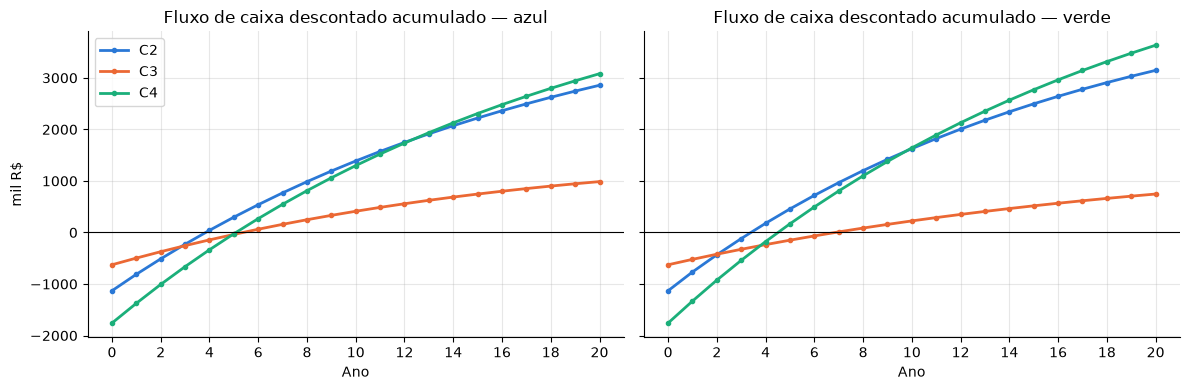

In [24]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, modalidade in zip(eixos, ('azul', 'verde')):
    for nome in ('C2', 'C3', 'C4'):
        ax.plot(np.cumsum(fluxos[(nome, modalidade)] * desconto) / 1000, label=nome, marker='o', markersize=3)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set(title=f'Fluxo de caixa descontado acumulado — {modalidade}', xlabel='Ano', xticks=range(0, ANOS + 1, 2))
eixos[0].set_ylabel('mil R$')
eixos[0].legend()
plt.tight_layout()

**Para discutir:** qual cenário e qual modalidade você recomendaria ao cliente? O que pesa mais no resultado do BESS: o CAPEX, a degradação ou a tarifa?

## 9. Exercícios

Mude a célula de **Premissas** (seção 1), rode tudo de novo e compare com os resultados acima.

1. **Custo da bateria**: com que `CAPEX_BESS` o VPL do C3 zera na verde? E na azul?
2. **Taxa de desconto**: refaça com `TAXA_DESCONTO = 0.10`. Qual cenário sofre mais? Por quê?
3. **Peak shaving**: mude `LIMITE_PEAK_SHAVING_KW` para 100 e para 140. O que acontece com a demanda contratada e com a conta da azul?
4. **Carga mais "nervosa"**: suba `PERCENTUAL_RUIDO` para 15. Como reagem o dimensionamento do BESS, a demanda contratada e as ultrapassagens ao longo dos 20 anos?
5. **Próxima vigência (Lei 14.300 avançando)**: na REH, a Tabela 4 da vigência 2027.1 traz `te_p = te_fp = 0.9917` na azul e `te_p = 0.2363`, `te_fp = 0.9917` na verde (as TUSD seguem com desconto integral). Troque em `DESCONTO_SCEE` e veja o efeito em C2.

## Referências

- ANEEL. **Resolução Homologatória nº 3.518/2025**: tarifas da Energisa Paraíba (TE, TUSD e Tabela 4, descontos do SCEE).
- ANEEL. **Resolução Normativa nº 1.000/2021**: regras de prestação do serviço; demanda contratada, ultrapassagem e SCEE (art. 655-G).
- ANEEL. **PRORET, Submódulo 7.1**: procedimentos gerais da estrutura tarifária.
- BRASIL. **Lei nº 14.300/2022**: marco legal da micro e minigeração distribuída.
- NASA. **POWER (Prediction Of Worldwide Energy Resources)**, dados horários: https://power.larc.nasa.gov/api/temporal/hourly/point
- CEPEL/CRESESB. **SunData**: irradiação solar (HSP de João Pessoa).
- CANADIAN SOLAR. **Datasheet HiKu7 Mono PERC CS7N-650MS**: https://www.csisolar.com/br/downloads?downid=18114
- ABSAE. **Custo dos sistemas de armazenamento em baterias segue em queda e amplia viabilidade no Brasil** (2025): https://www.absae.org.br/post/custo-dos-sistemas-de-armazenamento-em-baterias-segue-em-queda-e-amplia-viabilidade-no-brasil
- Biblioteca **holidays** (Python): feriados nacionais e estaduais.